<a href="https://colab.research.google.com/github/FadhilTaufiqurrachman/PCVK_Ganjil_2026-2027_FadhilTaufiqurrachman/blob/main/Week6PCVK.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Praktikum Pertemuan 6 - Spasial Filter

NIM : 244107020090

Nama : Fadhil Taufiqurrachman

Kelas : TI 3G

No Absen : 06

Mata Kuliah : Pengolahan Citra Dan Visi Komputer

In [ ]:
# Inisialisasi Identitas Mahasiswa
import sys, platform, hashlib, datetime, zoneinfo

NAMA = 'Fadhil Taufiqurrachman'
NIM = '244107020090'

waktu = datetime.datetime.now(zoneinfo.ZoneInfo('Asia/Jakarta'))

print('NAMA   :', NAMA)
print('NIM    :', NIM)
print('WAKTU  :', waktu.strftime('%Y-%m-%d %H:%M:%S %Z'))
print('SISTEM :', sys.version.split()[0], platform.platform())
kunci = NIM + '|' + waktu.strftime('%Y-%m-%d')
print('TOKEN  :', hashlib.sha256(kunci.encode()).hexdigest()[:16])

NAMA   : Fadhil Taufiqurrachman
NIM    : 244107020090
WAKTU  : 2026-10-02 09:21:17 WIB
SISTEM : 3.13.15 Linux-6.6.122+-x86_64-with-glibc2.39
TOKEN  : 29ea23b58e62cbe0


In [ ]:
# Connect To Google Drive For Image
from google.colab import drive
drive.mount('/content/drive')
BASE_PATH = '/content/drive/MyDrive/Education/Current Semester College File /PCVK Image/'

Mounted at /content/drive


### D. Praktikum Filter

Tahap 1

In [ ]:
# Import Library
import numpy as np
import matplotlib.pyplot as plt
import cv2 as cv
import math
from google.colab.patches import cv2_imshow
from PIL import Image as im

In [ ]:
def convolution2d(image, kernel, stride=1, padding=0):
    if padding > 0:
        image_padded = np.pad(image, pad_width=padding, mode='constant', constant_values=0)
    else:
        image_padded = image

    # Mengambil Dimensi Tinggi Dan Lebar
    image_h, image_w = image_padded.shape
    kernel_h, kernel_w = kernel.shape

    # Menghitung Dimensi Output
    output_h = (image_h - kernel_h) // stride + 1
    output_w = (image_w - kernel_w) // stride + 1

    output = np.zeros((output_h, output_w), dtype=np.float32)

    for y in range(0, output_h):
        for x in range(0, output_w):
            y_start = y * stride
            y_end = y_start + kernel_h
            x_start = x * stride
            x_end = x_start + kernel_w
            region = image_padded[y_start:y_end, x_start:x_end]
            output[y, x] = np.sum(region * kernel)

    # Clipping
    output = np.clip(output, 0, 255)

    # Mengubah Tipe Data
    return output.astype(np.uint8)

Tahap 2

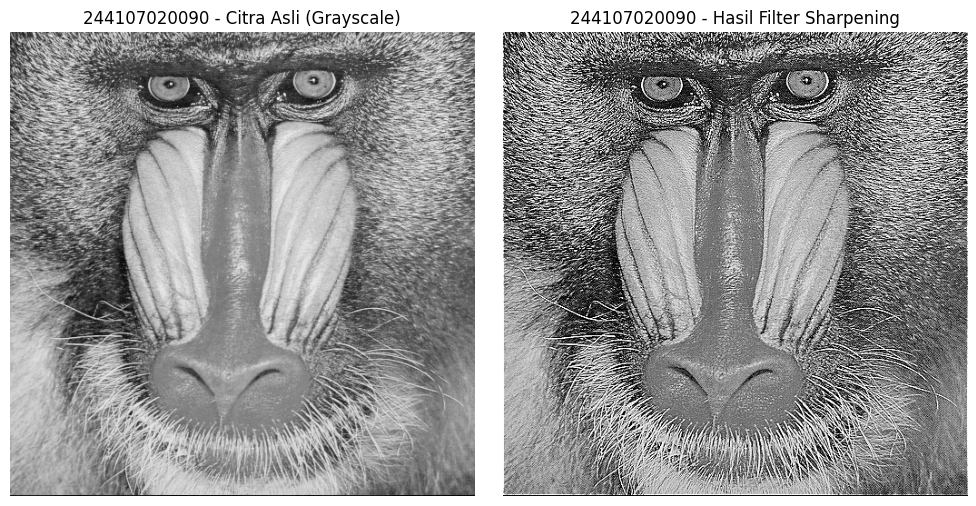

In [ ]:
img_path = BASE_PATH + 'mandrill.tiff'
img = cv.imread(img_path)
if img is None:
    print("Gambar Tidak Ditemukan, Silakan Cek Kembali Path Dan Nama File.")
else:
    # Mengubah Citra Menjadi Grayscale
    img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

    # Menentukan Kernel (Filter Sharpening)
    kernel_sharpen = np.array([[0, -1, 0],
                               [-1, 5, -1],
                               [0, -1, 0]])
    hasil_sharpen = convolution2d(img_gray, kernel_sharpen, stride=1, padding=1)

    plt.figure(figsize=(10, 5))

    plt.subplot(1, 2, 1)
    plt.imshow(img_gray, cmap='gray')
    plt.title('244107020090 - Citra Asli (Grayscale)')
    plt.axis('off')

    plt.subplot(1, 2, 2)
    plt.imshow(hasil_sharpen, cmap='gray')
    plt.title('244107020090 - Hasil Filter Sharpening')
    plt.axis('off')

    plt.tight_layout()
    plt.show()

Tahap 3

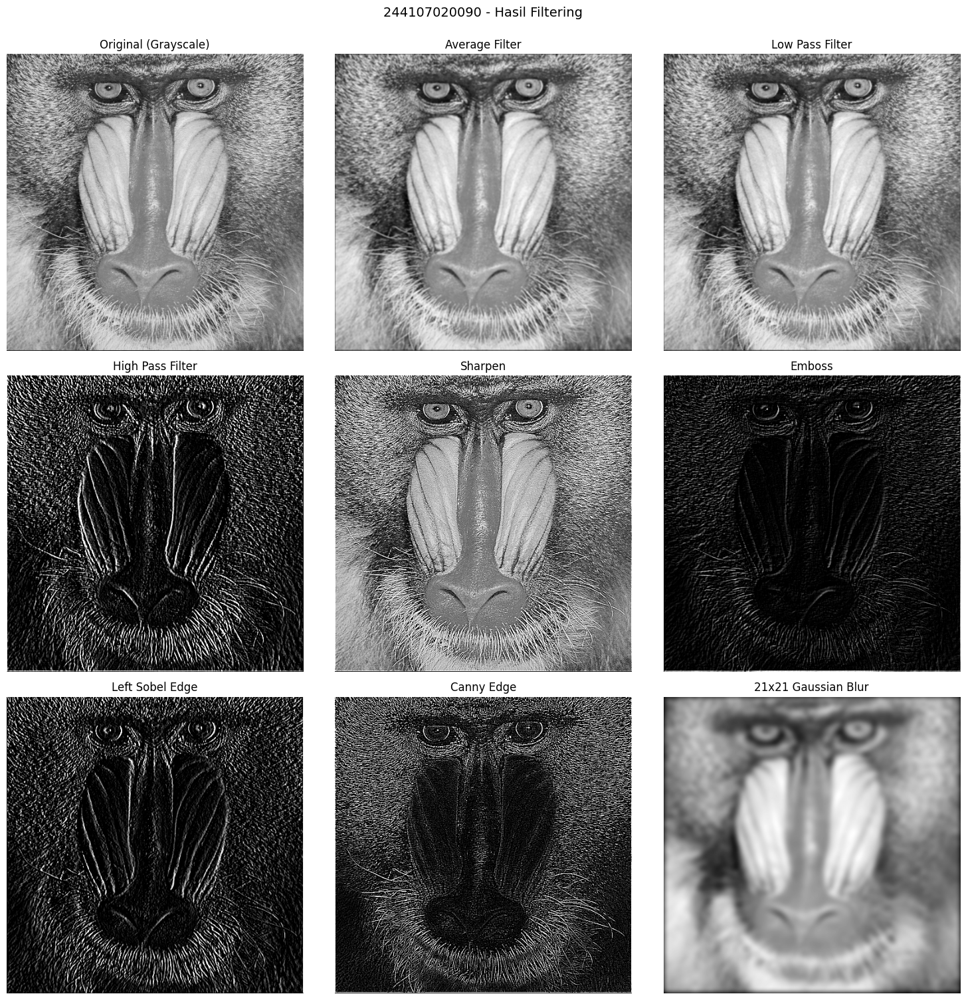

In [ ]:
img_path = BASE_PATH + 'mandrill.tiff'
img = cv.imread(img_path)
img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

# Filter Average (Rata-Rata)
kernel_average = np.array([[1, 1, 1],
                           [1, 1, 1],
                           [1, 1, 1]], dtype=np.float32) / 9.0

# Low Pass Filter
kernel_lpf = np.array([[1, 1, 1],
                       [1, 4, 1],
                       [1, 1, 1]], dtype=np.float32) / 12.0

# High Pass Filter
kernel_hpf = np.array([[-1, 0, 1],
                       [-1, 0, 3],
                       [-3, 0, 1]], dtype=np.float32)

# Filter Sharpen
kernel_sharpen = np.array([[0, -1, 0],
                           [-1, 5, -1],
                           [0, -1, 0]], dtype=np.float32)

# Filter Emboss
kernel_emboss = np.array([[1, 0, 0],
                          [0, 0, 0],
                          [0, 0, -1]], dtype=np.float32)

# Filter Left Sobel Edge Detection
kernel_left_sobel = np.array([[1, 0, -1],
                              [2, 0, -2],
                              [1, 0, -1]], dtype=np.float32)

# Filter Canny Edge Detection
kernel_canny = np.array([[-1, -1, -1],
                         [-1, 8, -1],
                         [-1, -1, -1]], dtype=np.float32)

# Filter Gaussian Blur 21x21
kernel_size = 21
sigma = math.sqrt(kernel_size)
gaussian_1d = cv.getGaussianKernel(kernel_size, sigma)
kernel_gaussian = gaussian_1d @ gaussian_1d.transpose()


# Menerapkan Fungsi Konvolusi Ke Masing-Masing Kernel
hasil_average = convolution2d(img_gray, kernel_average, stride=1, padding=1)
hasil_lpf = convolution2d(img_gray, kernel_lpf, stride=1, padding=1)
hasil_hpf = convolution2d(img_gray, kernel_hpf, stride=1, padding=1)
hasil_sharpen = convolution2d(img_gray, kernel_sharpen, stride=1, padding=1)
hasil_emboss = convolution2d(img_gray, kernel_emboss, stride=1, padding=1)
hasil_left_sobel = convolution2d(img_gray, kernel_left_sobel, stride=1, padding=1)
hasil_canny = convolution2d(img_gray, kernel_canny, stride=1, padding=1)
hasil_gaussian = convolution2d(img_gray, kernel_gaussian, stride=1, padding=10)


fig, axes = plt.subplots(3, 3, figsize=(15, 15))
fig.suptitle('244107020090 - Hasil Filtering', fontsize=14, y=1.0)
images = [img_gray, hasil_average, hasil_lpf,
          hasil_hpf, hasil_sharpen, hasil_emboss,
          hasil_left_sobel, hasil_canny, hasil_gaussian]
titles = ['Original (Grayscale)', 'Average Filter', 'Low Pass Filter',
          'High Pass Filter', 'Sharpen', 'Emboss',
          'Left Sobel Edge', 'Canny Edge', '21x21 Gaussian Blur']

for i, ax in enumerate(axes.flat):
    ax.imshow(images[i], cmap='gray')
    ax.set_title(titles[i])
    ax.axis('off')

plt.tight_layout()
plt.show()

Praktikum ini membuktikan bahwa nilai dari kernel akan sangat mempengaruhi hasil akhir dari citra asli yang dilakukan filtering. Satu fungsi konvulsi yang sama, dapat dimodifikasi nilai kernel matriksnya untuk menghasilkan jenis filtering yang berbeda. Setiap jenis filtering memiliki aturan nilai atau bobot kernelnya masing masing.

### E. Filter Library Dan Filter Modern

Percobaan 1

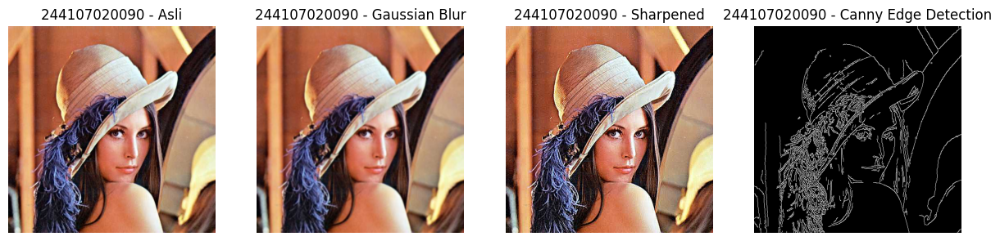

In [ ]:
# Fungsi Tampil Berdampingan Untuk Menampilkan Beberapa Gambar Sekaligus
def show_side_by_side(images, titles, figsize=(15,5)):
    plt.figure(figsize=figsize)
    for i, (img, title) in enumerate(zip(images, titles)):
        if len(img.shape) == 2:
            plt.subplot(1, len(images), i+1)
            plt.imshow(img, cmap="gray")
        else:
            plt.subplot(1, len(images), i+1)
            plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))

        plt.title(title)
        plt.axis("off")
    plt.show()

img_path = BASE_PATH + 'lena.jpg'
img = cv.imread(img_path)

if img is None:
    print("Gambar Tidak Ditemukan, Silakan Cek Kembali Path Dan Nama File.")
else:
    # Menerapkan Gaussian Blur Menggunakan Fungsi Bawaan OpenCV
    blur = cv.GaussianBlur(img, (7,7), 1)

    # Menerapkan Deteksi Tepi Canny
    edges = cv.Canny(cv.cvtColor(img, cv.COLOR_BGR2GRAY), 100, 200)

    # Mendefinisikan Kernel Sharpening Dan Menerapkannya Memakai Fungsi Filter2D
    sharpen_kernel = np.array([[0, -1, 0],
                               [-1, 5, -1],
                               [0, -1, 0]])
    sharpened = cv.filter2D(img, -1, sharpen_kernel)

    show_side_by_side([img, blur, sharpened, edges],
                      ["244107020090 - Asli", "244107020090 - Gaussian Blur", "244107020090 - Sharpened",
                       "244107020090 - Canny Edge Detection"])

Pada praktikum sebelumnya kita melakukan perhitungan konvolusi manual, sekarang kita mencoba fungsi bawaan library OpenCV yang sudah dioptimasi untuk menghitung konvolusi. Dengan fungsi fungsi tersebut kita dapat menerapkan efek seperti pengaburan, penajaman hingga deteksi tepi tingkat lanjut secara instan dan praktis. Sehingga sangat mempermudah tanpa menyusun algoritma matematika dan looping piksel dari nol.

Percobaan 2

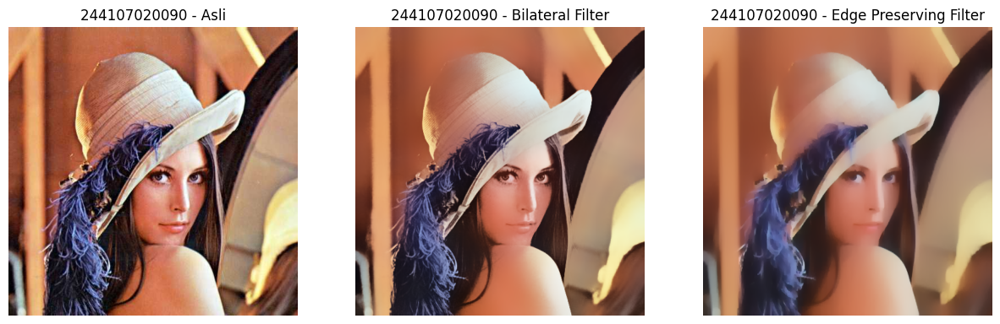

In [ ]:
img_path = BASE_PATH + 'lena.jpg'
img = cv.imread(img_path)
if img is None:
    print("Gambar Tidak Ditemukan, Silakan Cek Kembali Path Dan Nama File.")
else:
    # 1. Bilateral Filter (Filter Penghalus Yang Mempertahankan Tepi)
    bilateral = cv.bilateralFilter(img, 50, 100, 100)

    # 2. Edge Preserving Filter
    edge_preserve = cv.edgePreservingFilter(img, flags=1, sigma_s=100, sigma_r=0.9)

    show_side_by_side([img, bilateral, edge_preserve],
                      ["244107020090 - Asli", "244107020090 - Bilateral Filter", "244107020090 - Edge Preserving Filter"])

Dua filter di atas mempertimbangkan perbedaan intensitas warna antar piksel. Maka dari itu filter dapat memperbagus area datar seperti memperhalus tekstur kulit tanpa mengaburkan detail penting seperti garis tepi wajah. Filter filter inilah yang dijadikan sebagai dasar efek dan perbaikan foto beauty pada aplikasi zaman modern saat ini.

Percobaan 3

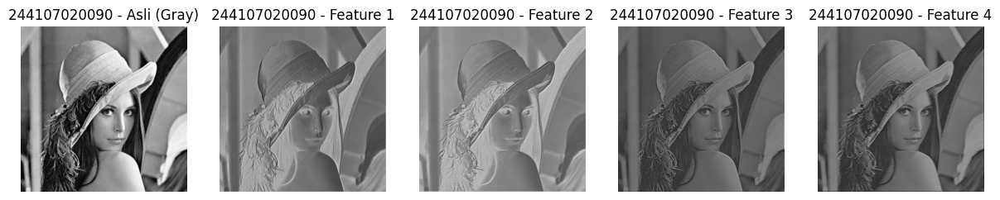

In [ ]:
# Import Library Untuk CNN
import torch
import torch.nn as nn

img_path = BASE_PATH + 'lena.jpg'
img = cv.imread(img_path)
img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

# Mendefinisikan Arsitektur CNN Sederhana
class SimpleCNN(nn.Module):
    def __init__(self):
        super(SimpleCNN, self).__init__()
        # Membuat Layer Konvolusi Dengan 1 Input Channel (Grayscale), 4 Output Channel (Feature Maps), Dan Kernel 3x3
        self.conv1 = nn.Conv2d(1, 4, kernel_size=3, stride=1, padding=1)

    def forward(self, x):
        return self.conv1(x)

# Menginisialisasi Model CNN
model = SimpleCNN()

# Mengubah Gambar Menjadi Tensor Dan Normalisasi Nilai Piksel Ke Rentang 0.0 - 1.0
img_tensor = torch.tensor(img_gray, dtype=torch.float32).unsqueeze(0).unsqueeze(0) / 255.0

# Mendapatkan Hasil Ekstraksi Fitur (Feature Map) Dari CNN Tanpa Menghitung Gradien (Karena Tidak Sedang Training)
with torch.no_grad():
    features = model(img_tensor)

# Visualisasi Feature Maps
feature_maps = [features[0, i].numpy() for i in range(features.shape[1])]
show_side_by_side([img_gray] + feature_maps,
                  ["244107020090 - Asli (Gray)"] + [f"244107020090 - Feature {i+1}" for i in range(len(feature_maps))])

Percobaan ini merupakan simulasi dari arsitektur CNN yang dibuat secara sederhana. Hasil disetiap feature akan selalu berubah ubah karena konvolusinya diisi dengan kernel matriks random atau angka acak. Sehingga jika dijalankan berulang kali akan menghasilkan citra output yang berbeda beda. Dalam model Deep Learning sungguhan, Nilai bobot acak ini yang akan ditrainingkan ke CNN agar mendapatkan hasil citra yang terbaik.

Percobaan 4

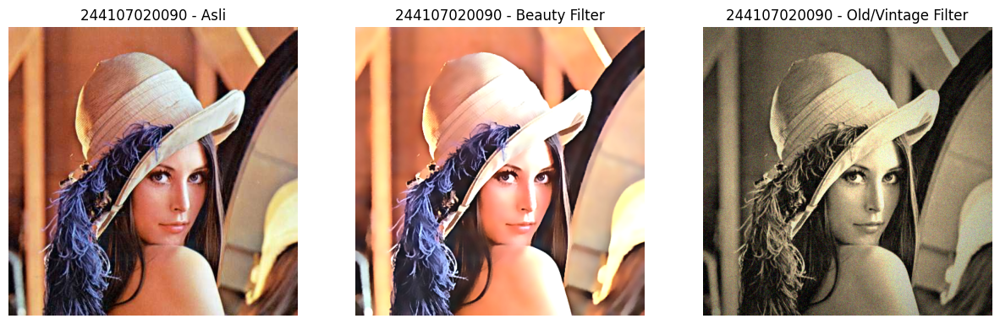

In [ ]:
img_path = BASE_PATH + 'lena.jpg'
img = cv.imread(img_path)

if img is None:
    print("Gambar Tidak Ditemukan, Silakan Cek Kembali Path Dan Nama File.")
else:
    # =====================
    # 1. Beauty Filter
    # =====================

    # Step 1: Smoothing Kulit Dengan Bilateral Filter
    smooth = cv.bilateralFilter(img, d=15, sigmaColor=75, sigmaSpace=75)

    # Step 2: Unsharp Masking (Pertajam Mata/Bibir)
    gaussian = cv.GaussianBlur(smooth, (0, 0), 3)
    sharpened = cv.addWeighted(smooth, 1.5, gaussian, -0.5, 0)

    # Step 3: Brightness & Contrast
    alpha = 1.2  # Contrast
    beta = 15    # Brightness
    beauty = cv.convertScaleAbs(sharpened, alpha=alpha, beta=beta)

    # =====================
    # 2. Old/Vintage Filter
    # =====================

    # Step 1: Sepia Tone
    sepia_kernel = np.array([[0.272, 0.534, 0.131],
                             [0.349, 0.686, 0.168],
                             [0.393, 0.769, 0.189]])
    sepia = cv.transform(img, sepia_kernel)
    sepia = np.clip(sepia, 0, 255).astype(np.uint8)

    # Step 2: Vignette
    rows, cols = img.shape[:2]
    kernel_x = cv.getGaussianKernel(cols, cols * 0.6)
    kernel_y = cv.getGaussianKernel(rows, rows * 0.6)
    kernel = kernel_y * kernel_x.T
    mask = kernel / kernel.max()
    vignette = np.copy(sepia)
    for i in range(3):
        vignette[:, :, i] = vignette[:, :, i] * mask

    # Step 3: Noise/Grain
    noise = np.random.normal(0, 15, vignette.shape).astype(np.int16)
    old_img = np.clip(vignette.astype(np.int16) + noise, 0, 255).astype(np.uint8)

    show_side_by_side([img, beauty, old_img],
                      ["244107020090 - Asli", "244107020090 - Beauty Filter", "244107020090 - Old/Vintage Filter"])

Pada Beauty Filter, menggunakan jenis Bilateral Filter untuk memperhalus kulit, kemudian digabung dengan Unsharp Masking agar detail mata tetap tajam dan peningkatan kecerahan. Sementara pada Vintage Filter, mengubah ruang warna menjadi Sepia, lalu menambahkan matriks Vignette dan noise buatan untuk kesan ilusi foto tua atau zaman dulu yang kusam dan bertekstur.

Percobaan 5

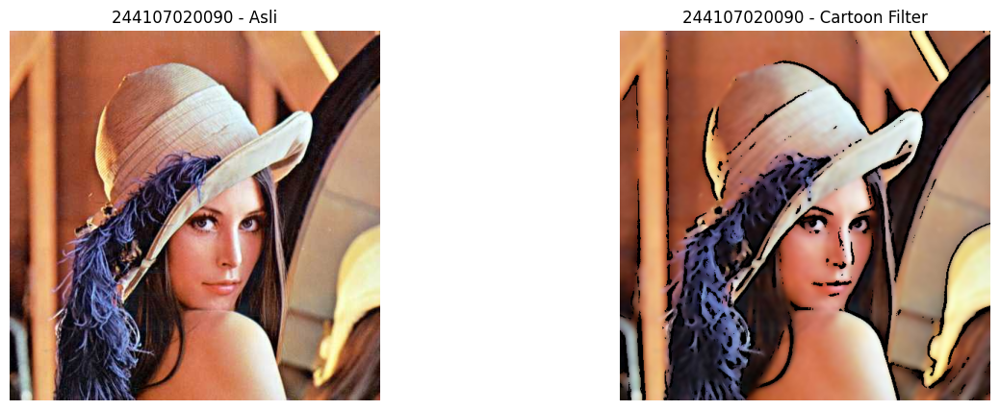

In [ ]:
img_path = BASE_PATH + 'lena.jpg'
img = cv.imread(img_path)

if img is None:
    print("Gambar Tidak Ditemukan, Silakan Cek Kembali Path Dan Nama File.")
else:
    # Filter Anime / Cartoon
    # Step 1: Edge Detection
    gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
    gray_blur = cv.medianBlur(gray, 7)
    edges = cv.adaptiveThreshold(gray_blur, 255,
                                 cv.ADAPTIVE_THRESH_MEAN_C,
                                 cv.THRESH_BINARY, 9, 9)

    # Step 2: Bilateral Filter Untuk Smoothing Warna
    color = cv.bilateralFilter(img, d=9, sigmaColor=200, sigmaSpace=200)

    # Step 3: Gabungkan (Cartoonize)
    cartoon = cv.bitwise_and(color, color, mask=edges)

    show_side_by_side([img, cartoon], ["244107020090 - Asli", "244107020090 - Cartoon Filter"])

Percobaan kali ini mencoba untuk membuat efek kartun melalui beberapa tahap. Yang pertama yakni Edge Detection untuk mengekstrak garis tepi lalu menebalkannya dengan Adaptive Thresholding. Kemudian yang kedua yaitu menghilangkan detail tekstur menggunakan Bilateral Filter. Dan yang terakhir garis tepi yang dihasilkan sebelumnya ditumpuk sehingga tercipta visual mirip karakter kartun atau komik.

Percobaan 6

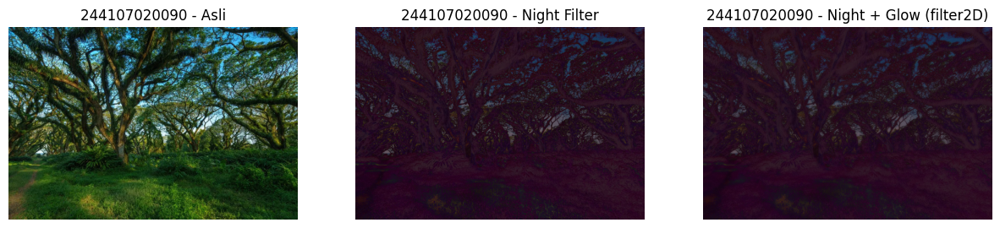

In [ ]:
img_path = BASE_PATH + 'djawatan.jpg'
img = cv.imread(img_path)

if img is None:
    print("Gambar Tidak Ditemukan, Silakan Cek Kembali Path Dan Nama File Anda.")
else:
    img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

    night = cv.convertScaleAbs(img, alpha=0.6, beta=-40)

    blue_tint = np.full_like(night, (50, 0, 100)) # Format BGR
    night = cv.addWeighted(night, 0.8, blue_tint, 0.2, 0)

    kernel = np.ones((15, 15), np.float32) / 225
    glow = cv.filter2D(night, -1, kernel)

    night_glow = cv.addWeighted(night, 0.7, glow, 0.3, 0)

    show_side_by_side([img, night, night_glow],
                      ["244107020090 - Asli", "244107020090 - Night Filter", "244107020090 - Night + Glow (filter2D)"])

Percobaan ini merupakan trik manipulasi waktu dan suasana dalam foto. Dimulai dengan menurunkan kecerahan dan kontras piksel. Kemudian suasana tersebut akan diperkuat dengan menambahkan bias warna biru keunguan agar seperti kesan dingin dari cahaya bulan

Percobaan 7

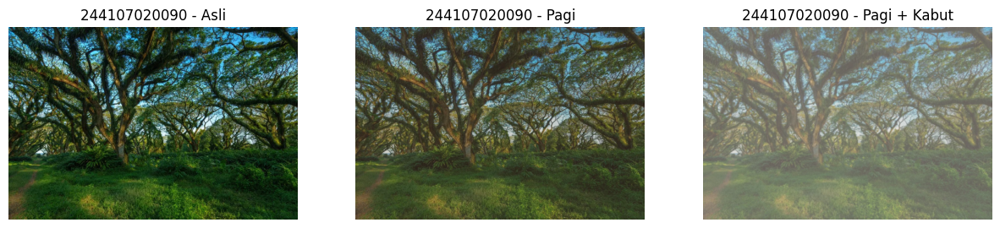

In [ ]:
# Fungsi Untuk Menampilkan Gambar Berdampingan
def show_side_by_side(images, titles, figsize=(15, 5)):
    plt.figure(figsize=figsize)
    for i, (img, title) in enumerate(zip(images, titles)):
        plt.subplot(1, len(images), i+1)
        if len(img.shape) == 2:  # Skala Abu Abu
            plt.imshow(img, cmap="gray")
        else:  # Berwarna
            plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
        plt.title(title)
        plt.axis("off")
    plt.show()
img = cv.imread(BASE_PATH + 'djawatan.jpg')

# Filter Suasana Pagi Dan Kabut
# ==========================================

# Step 1: Kurangi Kontras Dan Cerahkan
alpha = 0.9
beta = 20
soft = cv.convertScaleAbs(img, alpha=alpha, beta=beta)

# Step 2: Tambahkan Warm Tone (Kemerahan Atau Oranye)
warm_tint = np.full_like(soft, (40, 70, 120))  # Format BGR
pagi = cv.addWeighted(soft, 0.8, warm_tint, 0.2, 0)

# Step 3: Tambahkan Haze (Kabut Tipis) Dengan Filter2D
# Kernel Blur Gaussian Untuk Menciptakan Efek Kabut
kernel = cv.getGaussianKernel(3, 3)
kernel = kernel @ kernel.T
kabut = cv.filter2D(pagi, -1, kernel)

# Tambah Layer Putih Untuk Kabut Lebih Nyata
white_layer = np.full_like(pagi, 255)
kabut = cv.addWeighted(kabut, 0.7, white_layer, 0.3, 0)

show_side_by_side([img, pagi, kabut], ["244107020090 - Asli", "244107020090 - Pagi", "244107020090 - Pagi + Kabut"])

Efek filter suasana pagi berkabut dibuat dengan tahap penyesuaian intensitas piksel dan manipulasi lapisan warna. Proses awal dilakukan dengan melunakkan ketajaman citra dan meningkatkan nilai kecerahan agar gambar tidak terlihat terlalu gelap. Kemudian diberi sentuhan warna dominan jingga/kemerahan (dengan bobot 20%) untuk mensimulasikan pancaran sinar matahari pagi yang hangat. Terakhir, citra dihaluskan secara spasial menggunakan Gaussian Kernel dan ditumpuk dengan lapisan kanvas berwarna putih solid beropasitas 30%, sehingga secara visual seolah-olah terdapat partikel kabut tipis yang menghalangi pandangan.

### Tugas Praktikum

1. Perbandingan Mean Filter (Blur Biasa) vs. Median Filter pada Noise “Salt and
Pepper”

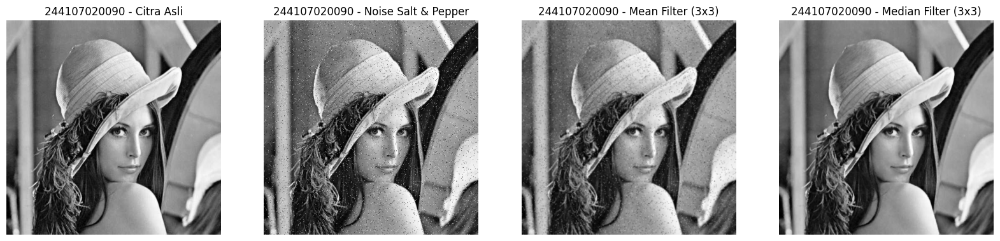

In [ ]:
img_asli = cv.imread(BASE_PATH + 'lena.jpg', cv.IMREAD_GRAYSCALE)

# Membuat Salinan Citra Untuk Diberi Noise
img_noise = np.copy(img_asli)

# Menambahkan Noise Bintik Hitam Dan Putih (Salt And Pepper)
# Menggunakan Masking Nilai Random Untuk Menentukan Posisi Noise
matriks_random = np.random.rand(*img_noise.shape)
img_noise[matriks_random < 0.02] = 0    # Pepper (Hitam)
img_noise[matriks_random > 0.98] = 255  # Salt (Putih)

# Menerapkan Mean Filter Dengan Ukuran Kernel 3x3
img_mean = cv.blur(img_noise, (3, 3))

# Menerapkan Median Filter Dengan Ukuran Kernel 3x3
img_median = cv.medianBlur(img_noise, 3)

plt.figure(figsize=(20, 5))

plt.subplot(1, 4, 1)
plt.imshow(img_asli, cmap='gray')
plt.title('244107020090 - Citra Asli')
plt.axis('off')

plt.subplot(1, 4, 2)
plt.imshow(img_noise, cmap='gray')
plt.title('244107020090 - Noise Salt & Pepper')
plt.axis('off')

plt.subplot(1, 4, 3)
plt.imshow(img_mean, cmap='gray')
plt.title('244107020090 - Mean Filter (3x3)')
plt.axis('off')

plt.subplot(1, 4, 4)
plt.imshow(img_median, cmap='gray')
plt.title('244107020090 - Median Filter (3x3)')
plt.axis('off')

plt.show()

Berdasarkan hasil tersebut, Median Filter menghasilkan citra yang lebih bersih dalam menghapus noise Salt and Pepper dibandingkan dengan Mean Filter. Hal ini terjadi karena Mean Filter bekerja dengan merata-rata seluruh nilai intensitas piksel di dalam kernel 3x3, sehingga keberadaan nilai ekstrem dari noise akan ikut terhitung, mendistorsi nilai rata-rata, dan justru membuat bintik noise tersebut memudar lalu menyebar seperti noda kotor pada citra. Berbeda dengan Median Filter, filter ini akan mengurutkan seluruh nilai piksel tetangga dan mengambil nilai tengahnya. Dikarenakan noise Salt and Pepper memiliki intensitas yang sangat ekstrem, nilai tersebut akan selalu berada di ujung urutan dan diabaikan, sehingga piksel yang rusak tergantikan dengan sempurna oleh nilai piksel tetangganya yang wajar tanpa merusak ketajaman citra secara keseluruhan.

2. Pemilihan Ukuran Kernel terbaik untuk Menajamkan Citra (Sharpening)

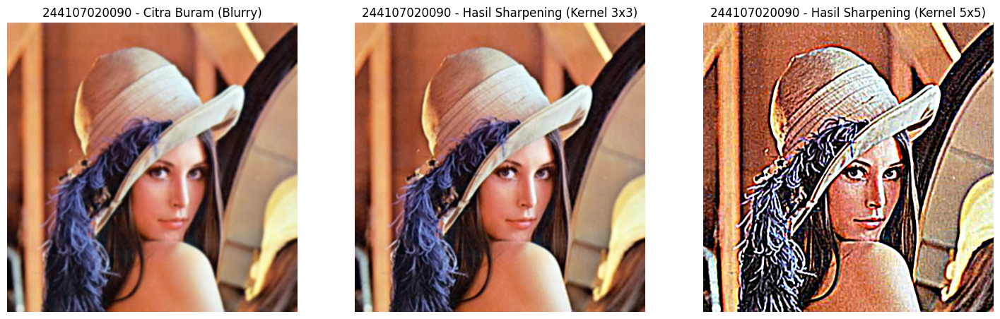

In [ ]:
img = cv.imread(BASE_PATH + 'lena.jpg')
img_rgb = cv.cvtColor(img, cv.COLOR_BGR2RGB)

# Mensimulasikan Citra Yang Sedikit Buram (Blurry) Menggunakan Gaussian Blur
img_blurry = cv.GaussianBlur(img_rgb, (7, 7), 0)

# Membuat Kernel Sharpening Ukuran 3x3
kernel_3x3 = np.array([[ 0, -1,  0],
                       [-1,  5, -1],
                       [ 0, -1,  0]])

# Membuat Kernel Sharpening Ukuran 5x5
# Menggunakan Nilai -1 Di Sekeliling Dan 25 Di Tengah Agar Total Bobot = 1
kernel_5x5 = np.ones((5, 5)) * -1
kernel_5x5[2, 2] = 25

# Menerapkan Filter Sharpening Pada Citra Yang Buram
img_sharp_3x3 = cv.filter2D(img_blurry, -1, kernel_3x3)
img_sharp_5x5 = cv.filter2D(img_blurry, -1, kernel_5x5)

plt.figure(figsize=(18, 6))

plt.subplot(1, 3, 1)
plt.imshow(img_blurry)
plt.title('244107020090 - Citra Buram (Blurry)')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(img_sharp_3x3)
plt.title('244107020090 - Hasil Sharpening (Kernel 3x3)')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(img_sharp_5x5)
plt.title('244107020090 - Hasil Sharpening (Kernel 5x5)')
plt.axis('off')

plt.show()

Berdasarkan hasil citra di atas, kernel berukuran 3x3 adalah pilihan yang paling bagus dan optimal untuk digunakan menajamkan citra. Kernel 3x3 bisa membuat kejelasan garis tepi secara tepat sehingga detail objek terlihat tajam tanpa merusak kualitas citra foto secara keseluruhan. Namun sebaliknya, kernel berukuran 5x5 menghasilkan efek penajaman yang terlalu agresif. Meskipun garis tepi menjadi sangat kontras, tetapi hal ini dapat menyebabkan distorsi noise secara masif yang membuat gambar terlihat berpasir atau bertekstur. Kemudian juga memunculkan warna yang tidak alami terlalu over, serta merusak kehalusan tekstur pada area gambar yang seharusnya datar.

3.  Filter Kartun Sederhana

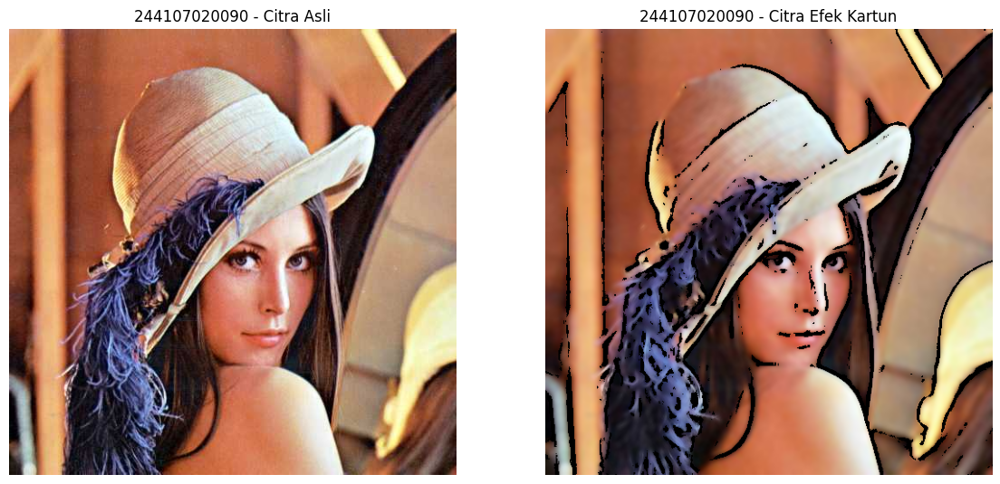

In [ ]:
def kartun(image):
    # Mengubah Citra Menjadi Grayscale Untuk Mempermudah Deteksi Tepi
    gray = cv.cvtColor(image, cv.COLOR_BGR2GRAY)

    # Menghaluskan Citra Grayscale Menggunakan Median Blur Agar Garis Tepi Lebih Bersih
    gray_blur = cv.medianBlur(gray, 7)

    # Mendeteksi Garis Tepi Menggunakan Adaptive Thresholding
    edges = cv.adaptiveThreshold(gray_blur, 255, cv.ADAPTIVE_THRESH_MEAN_C, cv.THRESH_BINARY, 9, 9)

    # Menghaluskan Area Warna Menggunakan Bilateral Filter
    color = cv.bilateralFilter(image, d=9, sigmaColor=200, sigmaSpace=200)

    cartoon_image = cv.bitwise_and(color, color, mask=edges)
    return cartoon_image

img_asli = cv.imread(BASE_PATH + 'lena.jpg')
img_hasil = kartun(img_asli)

img_asli_rgb = cv.cvtColor(img_asli, cv.COLOR_BGR2RGB)
img_hasil_rgb = cv.cvtColor(img_hasil, cv.COLOR_BGR2RGB)

plt.figure(figsize=(14, 7))

plt.subplot(1, 2, 1)
plt.imshow(img_asli_rgb)
plt.title('244107020090 - Citra Asli')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(img_hasil_rgb)
plt.title('244107020090 - Citra Efek Kartun')
plt.axis('off')

plt.show()

Proses efek visual kartun dimulai dengan pemerataan area warna (Warna flat) pada citra asli menggunakan Bilateral Filter. Kemudian dilakukan deteksi garis tepi yang tebal dan hitam menggunakan Adaptive Thresholding. Terakhir, citra warna flat tadi ditumpuk dengan sketsa batas objeknya melalui operasi penggabungan piksel, menghasilkan gambar kartun.